# PAF Project Group 6 — Task 3: Predictive Modelling
## Golden Hour Fatality Triage

**Contributors:** Joao (Person 1): problem framing, metrics & baseline · Pedro (Person 4): tree-based ensembles · Nuno (Person 5): non-tree models

**Business question.** When an emergency call arrives (t=0), should the dispatcher send a standard patrol / basic ambulance, or an immediate Advanced Life Support (ALS) unit or helicopter?

**Prediction.** Probability that the crash is fatal (`is_fatal = 1` when `accident_classification == 2`), using only information known at call intake.

This notebook reproduces the problem framing, metrics and baseline benchmark defined by Joao (see `contributions/person1_joao_problem_framing/`). Pedro and Nuno add their models in Section 7 and are evaluated with the same functions.

**Run `Task2_Data_Understanding_Preparation.ipynb` first:** it cleans the data, engineers the features, makes the split and saves them to `data/processed/`.

| Section | Content |
|---|---|
| 1 | Setup & loading the prepared data (from Task 2) |
| 2 | Data preparation recap |
| 3 | Target & base rates |
| 4 | Out-of-time split & feature sets |
| 5 | Metrics: why not accuracy, Top-15% rule, economic threshold p* |
| 6 | Baseline benchmark: Dummy vs. Balanced Logistic Regression |
| 7 | Advanced models (Pedro & Nuno) |

## 1. Setup & data loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib
import json

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
# Prepared by Task2_Data_Understanding_Preparation.ipynb (Section 9).
# Works locally (repo layout) and in Colab (upload the files from data/processed/).
PROCESSED = Path("../data/processed")
if not (PROCESSED / "train.csv").exists():
    from google.colab import files
    files.upload()  # train.csv, val.csv, test.csv, features.json, preprocessor.joblib
    PROCESSED = Path(".")

train = pd.read_csv(PROCESSED / "train.csv")
val = pd.read_csv(PROCESSED / "val.csv")
test = pd.read_csv(PROCESSED / "test.csv")
feature_lists = json.loads((PROCESSED / "features.json").read_text())
preprocessor = joblib.load(PROCESSED / "preprocessor.joblib")

df = pd.concat([train, val, test])
print(f"Prepared data: {len(df):,} rows (train {len(train):,} · val {len(val):,} · test {len(test):,})")

Prepared data: 149,999 rows (train 130,870 · val 9,073 · test 10,056)


## 2. Data preparation recap

Done in the Task 2 notebook (Section 9), based on the data-quality audit:
- **Dropped corrupted row 57163** (more than 10 missing features).
- **Imputed the 90 missing `road_direction` values** with the Train mode.
- **Excluded `latitude` / `longitude`**: 100% missing 2007–2016 (2017 GPS cliff).
- **Excluded `date` / `year`** as predictors: after the 2015 e-DAT reporting change, year captures *how crashes were logged*, not road risk.
- **Engineered features:** day of week, weekend flag, cyclical month, capped km, historical segment risk (fitted on Train only).

## 3. Target & base rates

Fatal crashes overall (2007-2025): 7,222 (4.81%)
Non-fatal overall:                 95.19%


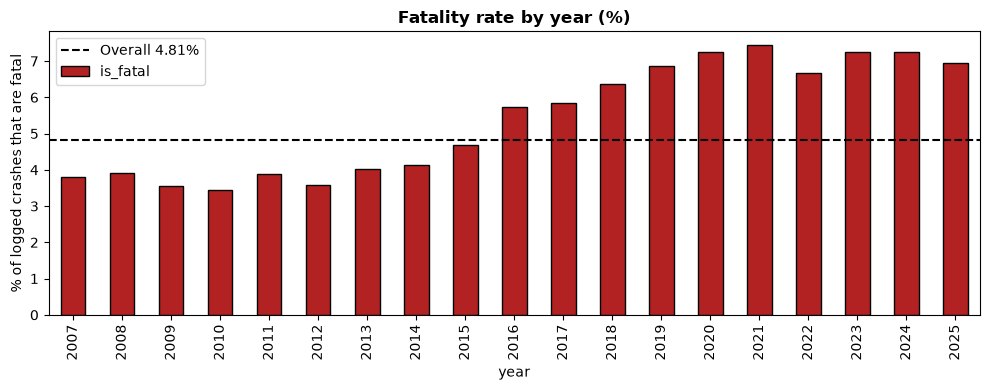

In [3]:
overall_rate = df["is_fatal"].mean()
print(f"Fatal crashes overall (2007-2025): {df['is_fatal'].sum():,} ({overall_rate:.2%})")
print(f"Non-fatal overall:                 {1 - overall_rate:.2%}")

rate_by_year = df.groupby("year")["is_fatal"].mean() * 100
ax = rate_by_year.plot(kind="bar", color="firebrick", edgecolor="black", figsize=(10, 4))
ax.axhline(overall_rate * 100, ls="--", color="black", label=f"Overall {overall_rate:.2%}")
ax.set_title("Fatality rate by year (%)", fontweight="bold")
ax.set_ylabel("% of logged crashes that are fatal")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Out-of-time split

No random shuffling: the model is trained on the past and evaluated on the most recent years, as it would be used in production. The split was made in the Task 2 notebook.

| Set | Years |
|---|---|
| Train | 2007–2021 |
| Validation | 2022–2023 |
| Test | 2024–2025 |

In [4]:
split_summary = pd.DataFrame({
    "Rows": [len(train), len(val), len(test)],
    "Fatal rate (%)": [s["is_fatal"].mean() * 100 for s in (train, val, test)],
}, index=["Train 2007-2021", "Validation 2022-2023", "Test 2024-2025"]).round(2)
split_summary

,Rows,Fatal rate (%)
Train 2007-2021,130870,4.49
Validation 2022-2023,9073,6.97
Test 2024-2025,10056,7.11


Two feature sets:
- **Baseline features** (19): the original road, location and time-of-day columns, as defined by Joao. Used for the baseline in Section 6.
- **Full features** (24): baseline plus the engineered features from Task 2. Used for the advanced models in Section 7, with the encoder and scaler fitted on Train (`preprocessor`).

In [5]:
BASE_CATEGORICAL = feature_lists["base_categorical"]
BASE_NUMERIC = feature_lists["base_numeric"]
BASE_FEATURES = BASE_CATEGORICAL + BASE_NUMERIC
FEATURES = feature_lists["categorical"] + feature_lists["numeric"]

y_train, y_val, y_test = train["is_fatal"], val["is_fatal"], test["is_fatal"]
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]

print(f"Baseline features ({len(BASE_FEATURES)}): {BASE_FEATURES}")
print(f"Full features ({len(FEATURES)}): {FEATURES}")
print("All known at t=0 (road geometry, location marker, calendar, time of day)")

Baseline features (19): ['roadway_type', 'area_type', 'time_of_day', 'highway_type', 'road_direction', 'km', 'Straight', 'Curve', 'Crossing', 'Downhill', 'Uphill', 'Road_Intersection', 'Roundabout', 'Regulated_Uturn', 'Roadworks', 'Overpass', 'Bridge', 'Temporary_Detour', 'Tunnel']
Full features (24): ['roadway_type', 'area_type', 'time_of_day', 'highway_type', 'road_direction', 'day_of_week', 'km_capped', 'Straight', 'Curve', 'Crossing', 'Downhill', 'Uphill', 'Road_Intersection', 'Roundabout', 'Regulated_Uturn', 'Roadworks', 'Overpass', 'Bridge', 'Temporary_Detour', 'Tunnel', 'is_weekend', 'month_sin', 'month_cos', 'segment_risk']
All known at t=0 (road geometry, location marker, calendar, time of day)


## 5. Metrics

### Why not accuracy
A model that always predicts "no fatality" looks excellent on accuracy but catches no deaths.

In [6]:
accuracy_always_no = 1 - y_test.mean()
print(f"'No fatality, ever' on the 2024-2025 test set: accuracy {accuracy_always_no:.2%}, recall 0.00%")

'No fatality, ever' on the 2024-2025 test set: accuracy 92.89%, recall 0.00%


### Metrics used
- **PR-AUC**: ranking quality on a rare event (a random model scores the base rate).
- **Recall / Precision / Lift @ Top 15%**: ALS capacity covers 15% of calls. Of all fatal crashes, how many fall in the 15% highest-risk calls, and how much better than random?
- **Brier score**: are the predicted probabilities trustworthy (calibration)? Lower is better.
- ROC-AUC reported for reference.

In [7]:
CAPACITY = 0.15  # share of calls that ALS can serve


def top_k_metrics(y_true, y_prob, k=CAPACITY):
    """Recall, precision and lift when dispatching ALS to the top-k share of highest-risk calls."""
    y_true = np.asarray(y_true)
    if np.ptp(y_prob) == 0:  # constant scores cannot rank: top-k is a random pick
        return k, y_true.mean(), 1.0
    n_top = int(np.ceil(len(y_true) * k))
    top_idx = np.argsort(-y_prob, kind="stable")[:n_top]
    recall = y_true[top_idx].sum() / y_true.sum()
    precision = y_true[top_idx].mean()
    return recall, precision, recall / k


def evaluate(name, y_true, y_prob):
    recall, precision, lift = top_k_metrics(y_true, y_prob)
    return pd.Series({
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Recall@15%": recall,
        "Precision@15%": precision,
        "Lift@15%": lift,
        "Brier": brier_score_loss(y_true, y_prob),
    }, name=name)

### Economic threshold p*
Dispatching ALS costs about €2,500; a prevented death is valued at about €50,000. Dispatch is worth it when expected benefit exceeds cost:

$$p \cdot B > C \;\Rightarrow\; p^* = \frac{C}{B}$$

In [8]:
COST_ALS = 2_500
BENEFIT_PREVENTED_DEATH = 50_000
p_star = COST_ALS / BENEFIT_PREVENTED_DEATH
print(f"p* = {COST_ALS:,} / {BENEFIT_PREVENTED_DEATH:,} = {p_star:.1%}")
print(f"Test-set base rate = {y_test.mean():.2%} > p*, so capacity (Top 15%) is the binding constraint.")

p* = 2,500 / 50,000 = 5.0%
Test-set base rate = 7.11% > p*, so capacity (Top 15%) is the binding constraint.


## 6. Baseline benchmark

1. **Dummy classifier**: always predicts the majority class ("no fatality"), so every crash gets probability 0.
2. **Balanced Logistic Regression**: one-hot encoded categoricals + scaled numeric features, `class_weight="balanced"` to counter the 5% fatal rate. Preprocessing is fitted on Train only.

In [9]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train[BASE_FEATURES], y_train)
p_dummy = dummy.predict_proba(test[BASE_FEATURES])[:, 1]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), BASE_CATEGORICAL),
    ("num", StandardScaler(), BASE_NUMERIC),
])
logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])
logreg.fit(train[BASE_FEATURES], y_train)
p_logreg = logreg.predict_proba(test[BASE_FEATURES])[:, 1]

results = pd.DataFrame([
    evaluate("Dummy (Baseline)", y_test, p_dummy),
    evaluate("Balanced Logistic Regression", y_test, p_logreg),
])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552


### Comparison with Joao's reported numbers

The Dummy row reproduces exactly. The logistic regression lands slightly above Joao's figures: their exact feature set and preprocessing were not shared, so small differences are expected. **The numbers in this notebook are the reproducible ones to use on the slides.**

In [10]:
joao = pd.DataFrame({
    "ROC-AUC": [0.5000, 0.6643], "PR-AUC": [0.0711, 0.1158],
    "Recall@15%": [0.1500, 0.2895], "Precision@15%": [0.0711, 0.1372],
    "Lift@15%": [1.00, 1.93], "Brier": [0.0711, 0.2499],
}, index=results.index)

comparison = pd.concat({"Joao (reported)": joao, "This notebook": results}, axis=1)
comparison.T.round(4)

Dummy (Baseline)  Balanced Logistic Regression
Joao (reported) ROC-AUC                  0.5000                        0.6643
                PR-AUC                   0.0711                        0.1158
                Recall@15%               0.1500                        0.2895
                Precision@15%            0.0711                        0.1372
                Lift@15%                 1.0000                        1.9300
                Brier                    0.0711                        0.2499
This notebook   ROC-AUC                  0.5000                        0.6659
                PR-AUC                   0.0711                        0.1221
                Recall@15%               0.1500                        0.3119
                Precision@15%            0.0711                        0.1478
                Lift@15%                 1.0000                        2.0793
                Brier                    0.0711                        0.2552

### Calibration (open flag from Joao)

Class balancing inflates probabilities: the Brier score is much worse than the dummy's. Before applying p* = 5%, the probabilities are re-calibrated on the **validation** set (isotonic regression, model frozen). Ranking metrics barely change; Brier should drop sharply.

In [11]:
logreg_cal = CalibratedClassifierCV(FrozenEstimator(logreg), method="isotonic")
logreg_cal.fit(val[BASE_FEATURES], y_val)
p_logreg_cal = logreg_cal.predict_proba(test[BASE_FEATURES])[:, 1]

results = pd.concat([results, evaluate("Balanced LR + isotonic calibration", y_test, p_logreg_cal).to_frame().T])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552
Balanced LR + isotonic calibration,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645


In [12]:
dispatched = p_logreg_cal >= p_star
print(f"Calls above p* = {p_star:.0%}: {dispatched.mean():.1%} of test calls "
      f"(capacity is {CAPACITY:.0%})")
print(f"Fatal crashes among them: {y_test[dispatched].sum()} of {y_test.sum()} "
      f"({y_test[dispatched].sum() / y_test.sum():.1%})")

Calls above p* = 5%: 62.9% of test calls (capacity is 15%)
Fatal crashes among them: 592 of 715 (82.8%)


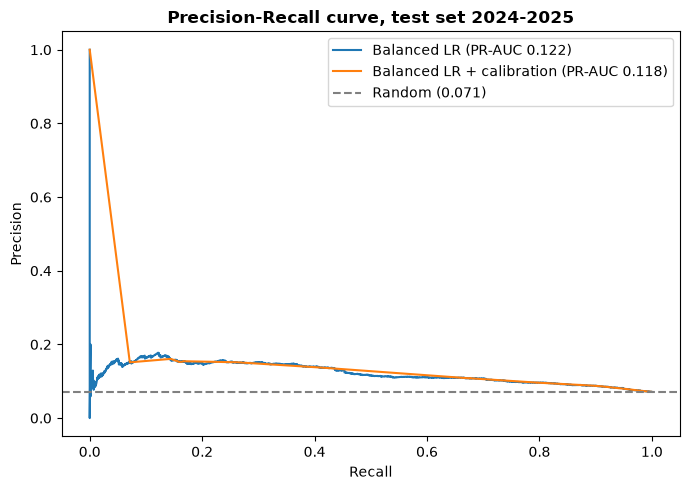

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in [("Balanced LR", p_logreg), ("Balanced LR + calibration", p_logreg_cal)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve, test set 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Advanced models (Pedro & Nuno)

Use the full feature set `X_train / X_val / X_test`, tune on **validation only**, and touch the test set once at the end.

- Linear models / neural nets: put the fitted `preprocessor` in front, e.g. `Pipeline([("prep", preprocessor), ("model", ...)])`. It is already fitted on Train, so wrap it with `FrozenEstimator(preprocessor)` to avoid refitting.
- Tree-based models (Random Forest, Gradient Boosting): the prepared columns can be used directly.
- Re-calibrate probabilities on validation before using p* (see Section 6).
- Worth testing (Task 2 finding): training on 2015–2021 only (`train[train["year"] >= 2015]`), after the e-DAT reporting change.

Add each model to the results table with:

```python
results = pd.concat([results, evaluate("My model", y_test, p_my_model).to_frame().T])
```

### 7.1 Model 1: Tree-based ensembles (Pedro)

**Why trees.** Fatality risk comes from combinations of conditions (e.g. rural *and* night *and* downhill), which a linear model can only capture if we hand-craft the interactions. Tree ensembles learn these interactions directly, need no scaling and handle the categorical codes natively.

Two ensemble strategies are compared:
- **Random Forest** (bagging): many deep, decorrelated trees averaged together. Robust, few hyperparameters.
- **Histogram Gradient Boosting** (boosting, scikit-learn's LightGBM-style implementation): shallow trees fitted one after another on the errors of the previous ones. Usually the strongest model on tabular data.

Both use class weights (`balanced`) to counter the 5% fatal rate, the same choice as the baseline. Hyperparameters are chosen on **Validation 2022–2023** by PR-AUC; the test set is used once, at the end.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance

CATEGORICAL = feature_lists["categorical"]


def make_rf(**params):
    return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=RANDOM_STATE, **params)


def make_hgb(**params):
    return HistGradientBoostingClassifier(class_weight="balanced", categorical_features=CATEGORICAL,
                                          min_samples_leaf=50, l2_regularization=1.0,
                                          early_stopping=False, random_state=RANDOM_STATE, **params)


def validation_score(model, X_fit=X_train, y_fit=y_train):
    # Fit on Train and score ranking quality on Validation (the test set is not touched)
    model.fit(X_fit, y_fit)
    p = model.predict_proba(X_val)[:, 1]
    _, _, lift = top_k_metrics(y_val, p)
    return {"PR-AUC (val)": average_precision_score(y_val, p), "Lift@15% (val)": lift}

#### Tuning on validation

A small grid per model. For Random Forest the key lever is how deep the trees grow (`max_depth`, `min_samples_leaf`); for Gradient Boosting it is the learning rate, tree size and number of trees.

In [15]:
rf_grid = [{"max_depth": d, "min_samples_leaf": leaf} for d in (8, 12, None) for leaf in (20, 50)]
hgb_grid = [{"learning_rate": lr, "max_leaf_nodes": leaves, "max_iter": n}
            for lr, leaves, n in [(0.1, 15, 300), (0.1, 31, 300), (0.03, 31, 300),
                                  (0.03, 15, 300), (0.03, 15, 150), (0.03, 7, 300), (0.01, 15, 600)]]

tuning = []
for params in rf_grid:
    tuning.append({"Model": "Random Forest", "Params": params, **validation_score(make_rf(**params))})
for params in hgb_grid:
    tuning.append({"Model": "Gradient Boosting", "Params": params, **validation_score(make_hgb(**params))})

tuning = pd.DataFrame(tuning).sort_values("PR-AUC (val)", ascending=False)
tuning.round(4)

,Model,Params,PR-AUC (val),Lift@15% (val)
10,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",0.1339,2.2363
12,Gradient Boosting,"{'learning_rate': 0.01, 'max_leaf_nodes': 15, ...",0.1328,2.1941
11,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 7, '...",0.1322,2.2679
9,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",0.1299,2.2363
8,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",0.1280,2.0992
1,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 50}",0.1273,2.0042
3,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 50}",0.1269,2.0148
0,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 20}",0.1262,1.9937
2,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 20}",0.1259,2.0464
5,Random Forest,"{'max_depth': None, 'min_samples_leaf': 50}",0.1259,2.0675


In [16]:
best_rf_params = tuning.loc[tuning["Model"] == "Random Forest", "Params"].iloc[0]
best_hgb_params = tuning.loc[tuning["Model"] == "Gradient Boosting", "Params"].iloc[0]
print(f"Best Random Forest:     {best_rf_params}")
print(f"Best Gradient Boosting: {best_hgb_params}")

Best Random Forest:     {'max_depth': 8, 'min_samples_leaf': 50}
Best Gradient Boosting: {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'max_iter': 150}


Smaller, more regularised models win on validation: deeper forests and more boosting rounds start fitting noise in the training years, which does not carry over to 2022–2023.

#### Training window: 2007–2021 vs. 2015–2021

The 2015 e-DAT reporting change (Task 2, Section 4) means older years were logged differently. We check whether training only on the post-change years helps.

In [17]:
recent = train["year"] >= 2015
window = pd.DataFrame({
    "2007-2021 (all Train)": validation_score(make_hgb(**best_hgb_params)),
    "2015-2021 (post e-DAT)": validation_score(make_hgb(**best_hgb_params), X_train[recent], y_train[recent]),
}).T
print(f"Rows: all Train {len(X_train):,} · post e-DAT {recent.sum():,}")
window.round(4)

Rows: all Train 130,870 · post e-DAT 39,540


,PR-AUC (val),Lift@15% (val)
2007-2021 (all Train),0.1339,2.2363
2015-2021 (post e-DAT),0.1355,2.1941


Both windows score about the same on validation. We keep **all Train years (2007–2021)**: more than twice the data for no loss in ranking, and the reporting drift is handled by re-calibrating the probabilities on validation.

#### Final fit, calibration and test-set scoring

The two tuned models are refitted on Train, re-calibrated on Validation (model frozen, as for the baseline in Section 6), and scored **once** on Test 2024–2025.

We use **sigmoid (Platt) calibration** rather than isotonic: isotonic regression maps scores to a step function, so many calls end up with the same probability and the Top-15% ranking gets blurred by ties. The sigmoid is strictly increasing, so it fixes the probabilities (Brier) while keeping the ranking of the model exactly as it is.

In [18]:
rf = make_rf(**best_rf_params).fit(X_train, y_train)
hgb = make_hgb(**best_hgb_params).fit(X_train, y_train)

rf_cal = CalibratedClassifierCV(FrozenEstimator(rf), method="sigmoid").fit(X_val, y_val)
hgb_cal = CalibratedClassifierCV(FrozenEstimator(hgb), method="sigmoid").fit(X_val, y_val)

p_rf, p_rf_cal = rf.predict_proba(X_test)[:, 1], rf_cal.predict_proba(X_test)[:, 1]
p_hgb, p_hgb_cal = hgb.predict_proba(X_test)[:, 1], hgb_cal.predict_proba(X_test)[:, 1]

results = pd.concat([results, pd.DataFrame([
    evaluate("Random Forest", y_test, p_rf),
    evaluate("Random Forest + sigmoid calibration", y_test, p_rf_cal),
    evaluate("Gradient Boosting", y_test, p_hgb),
    evaluate("Gradient Boosting + sigmoid calibration", y_test, p_hgb_cal),
])])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552
Balanced LR + isotonic calibration,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645
Random Forest,0.6640,0.1245,0.3119,0.1478,2.0793,0.2331
Random Forest + sigmoid calibration,0.6640,0.1245,0.3119,0.1478,2.0793,0.0645
Gradient Boosting,0.6729,0.1263,0.3147,0.1491,2.0979,0.2419
Gradient Boosting + sigmoid calibration,0.6729,0.1263,0.3147,0.1491,2.0979,0.0644


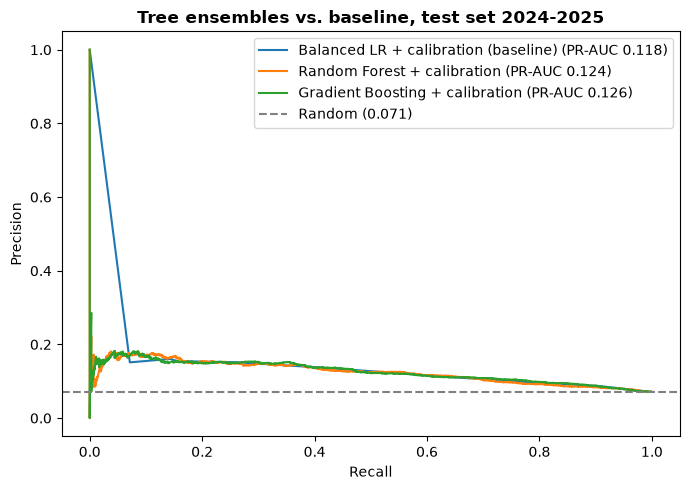

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in [("Balanced LR + calibration (baseline)", p_logreg_cal),
                ("Random Forest + calibration", p_rf_cal),
                ("Gradient Boosting + calibration", p_hgb_cal)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Tree ensembles vs. baseline, test set 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

#### What the model learned

Permutation importance on **Validation**: how much PR-AUC drops when one feature is randomly shuffled. Unlike the built-in tree importances, it is measured on unseen data and is not biased towards continuous features such as `km_capped`.

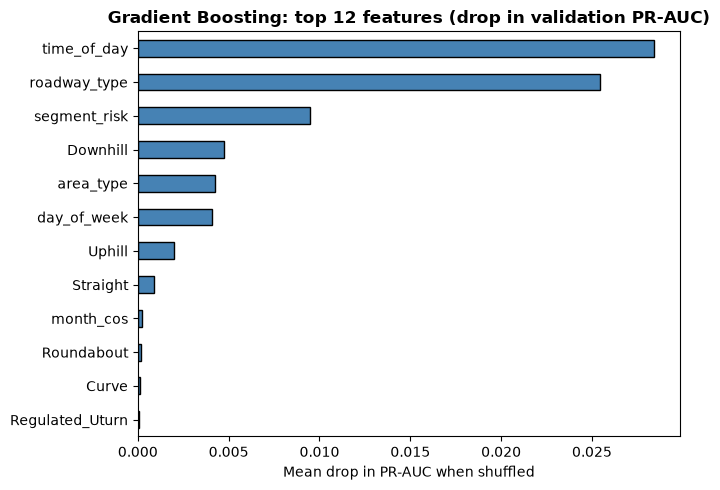

time_of_day     0.0284
roadway_type    0.0254
segment_risk    0.0095
Downhill        0.0048
area_type       0.0042
day_of_week     0.0041
Uphill          0.0020
Straight        0.0009
dtype: float64

In [20]:
perm = permutation_importance(hgb, X_val, y_val, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

ax = importance.tail(12).plot(kind="barh", color="steelblue", edgecolor="black", figsize=(7, 5))
ax.set_title("Gradient Boosting: top 12 features (drop in validation PR-AUC)", fontweight="bold")
ax.set_xlabel("Mean drop in PR-AUC when shuffled")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).head(8).round(4)

#### Dispatch impact

In [21]:
n_fatal = int(y_test.sum())
for name, p in [("Balanced LR + calibration", p_logreg_cal), ("Gradient Boosting + calibration", p_hgb_cal)]:
    recall, precision, lift = top_k_metrics(y_test, p)
    print(f"{name:33s} top 15% of calls -> {recall:.1%} of fatal crashes "
          f"({round(recall * n_fatal)} of {n_fatal}), lift {lift:.2f}x")

extra = (top_k_metrics(y_test, p_hgb_cal)[0] - top_k_metrics(y_test, p_logreg_cal)[0]) * n_fatal
print(f"\nSame ALS capacity: {extra:+.0f} fatal crashes reached in 2024-2025 with Gradient Boosting vs. the baseline.")
print(f"Calls above p* = {p_star:.0%}: {(p_hgb_cal >= p_star).mean():.1%} of test calls (capacity {CAPACITY:.0%}), "
      "so the Top-15% ranking stays the dispatch rule.")

Balanced LR + calibration         top 15% of calls -> 31.0% of fatal crashes (222 of 715), lift 2.07x
Gradient Boosting + calibration   top 15% of calls -> 31.5% of fatal crashes (225 of 715), lift 2.10x

Same ALS capacity: +3 fatal crashes reached in 2024-2025 with Gradient Boosting vs. the baseline.
Calls above p* = 5%: 57.8% of test calls (capacity 15%), so the Top-15% ranking stays the dispatch rule.


#### Takeaways (Pedro)

- **Gradient Boosting is the best tree model** (learning rate 0.03, 15 leaves, 150 trees): on Test 2024–2025 it reaches PR-AUC 0.126 and lift 2.10× at the Top 15%, against 0.122 and 2.08× for the balanced logistic regression. Random Forest ties with the baseline on ranking (lift 2.08×).
- **The gain over the baseline is small.** On Validation, boosting was clearly ahead (PR-AUC 0.134), but most of that edge does not carry over to the test years. With only road geometry, a km marker and calendar/time-of-day, the information available at t=0 caps how well any model can rank calls: the limit is the data, not the algorithm.
- **Calibration matters as much as the model.** Class weighting inflates probabilities (Brier 0.24); sigmoid calibration on Validation brings Brier to 0.064, in line with the base rate, without changing the ranking. Isotonic calibration was tried first but its ties cost about 1 point of recall at the Top 15%.
- **What drives the prediction:** time of day, roadway type (single vs. double carriageway) and the historical segment risk engineered in Task 2, followed by downhill segments, area type (rural) and day of week. These match the risk factors found in the EDA.
- **Training window:** using only post-2015 years gives the same validation ranking, so all Train years are kept.
- **For dispatch:** sending ALS to the 15% highest-risk calls reaches about 31% of fatal crashes, roughly twice what random allocation would reach. Since more than half of calls are above p* = 5%, capacity remains the binding constraint and the ranking is the decision rule.

### 7.2 Model 2 (Nuno)

In [22]:
# Nuno: model